# DSCI 552 — Homework 4

## Question 1 — From HW3

I use the same AReM data and train/test split as in HW3. The three feature
types I chose were mean, standard deviation, and maximum. I reuse them for
the scatter plots. For classification, I extract all seven feature types
and select features or apply regularization using only the training data.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown
from scipy.optimize import linprog
from scipy.special import expit, logit
from scipy.stats import norm
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score
)
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize

DATA_DIR = Path('data/AReM')
OUTPUT_DIR = Path('output')
OUTPUT_DIR.mkdir(exist_ok=True)
SEED = 552
sns.set_theme(style='whitegrid', context='notebook')
print('scikit-learn:', sklearn.__version__)

scikit-learn: 1.9.0


In [2]:
def load_instance(path):
    rows = []
    for line in path.read_text().splitlines():
        line = line.strip()
        if not line or line.startswith('#'):
            continue
        values = re.split(r'[,\s]+', line.rstrip(','))
        rows.append([float(x) for x in values])
    df = pd.DataFrame(rows, columns=['time'] + [f'ts{i}' for i in range(1, 7)])
    assert not df.empty and not df.isna().any().any()
    return df


instances = []
for folder in sorted(DATA_DIR.iterdir()):
    if not folder.is_dir():
        continue
    for file in sorted(folder.glob('dataset*.csv'),
                       key=lambda p: int(re.search(r'dataset(\d+)', p.stem).group(1))):
        dataset_id = int(re.search(r'dataset(\d+)', file.stem).group(1))
        test_ids = [1, 2] if folder.name in ['bending1', 'bending2'] else [1, 2, 3]
        df = load_instance(file)
        instances.append({
            'activity': folder.name,
            'dataset_id': dataset_id,
            'split': 'test' if dataset_id in test_ids else 'train',
            'data': df
        })
        if len(df) != 480:
            print(f'Using all {len(df)} available rows: {folder.name}/{file.name}')

metadata = pd.DataFrame([
    {k: x[k] for k in ['activity', 'dataset_id', 'split']}
    for x in instances
])
train_mask = metadata['split'].eq('train').to_numpy()
test_mask = ~train_mask
y_train = metadata.loc[train_mask, 'activity'].str.startswith('bending').astype(int).to_numpy()
y_test = metadata.loc[test_mask, 'activity'].str.startswith('bending').astype(int).to_numpy()
y_train_multi = metadata.loc[train_mask, 'activity'].to_numpy()
y_test_multi = metadata.loc[test_mask, 'activity'].to_numpy()
assert len(instances) == 88 and train_mask.sum() == 69 and test_mask.sum() == 19
display(pd.crosstab(metadata['activity'], metadata['split']))
print('Binary training counts (other, bending):', np.bincount(y_train))

Using all 479 available rows: sitting/dataset8.csv


split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


Binary training counts (other, bending): [60  9]


I retain the 479 observations in the short sitting recording rather than inventing
an extra row. `np.array_split` divides each recording into approximately equal
segments. Each original recording remains one sample.

In [3]:
def extract_features(df, l=1):
    features = {}
    for part, indices in enumerate(np.array_split(np.arange(len(df)), l), start=1):
        for i in range(1, 7):
            values = df[f'ts{i}'].iloc[indices]
            suffix = f'{i}_part{part}'
            features[f'min{suffix}'] = values.min()
            features[f'max{suffix}'] = values.max()
            features[f'mean{suffix}'] = values.mean()
            features[f'median{suffix}'] = values.median()
            features[f'std{suffix}'] = values.std(ddof=1)
            features[f'q1_{suffix}'] = values.quantile(0.25)
            features[f'q3_{suffix}'] = values.quantile(0.75)
    return features


features = {}
for l in range(1, 21):
    features[l] = pd.DataFrame([extract_features(x['data'], l) for x in instances])
    assert features[l].shape == (88, 42 * l)
    assert np.isfinite(features[l].to_numpy()).all()

X_train = {l: table.loc[train_mask].reset_index(drop=True) for l, table in features.items()}
X_test = {l: table.loc[test_mask].reset_index(drop=True) for l, table in features.items()}
pd.concat([metadata, features[1]], axis=1).to_csv(OUTPUT_DIR / 'features_l1.csv', index=False)
print('l=1:', X_train[1].shape, 'l=20:', X_train[20].shape)

l=1: (69, 42) l=20: (69, 840)


## Question 2(a) — Binary logistic regression
### (i) Scatter plots

Bending combines bending1 and bending2. I plot the mean, standard deviation,
and maximum of time series 1, 2, and 6, using only training recordings.

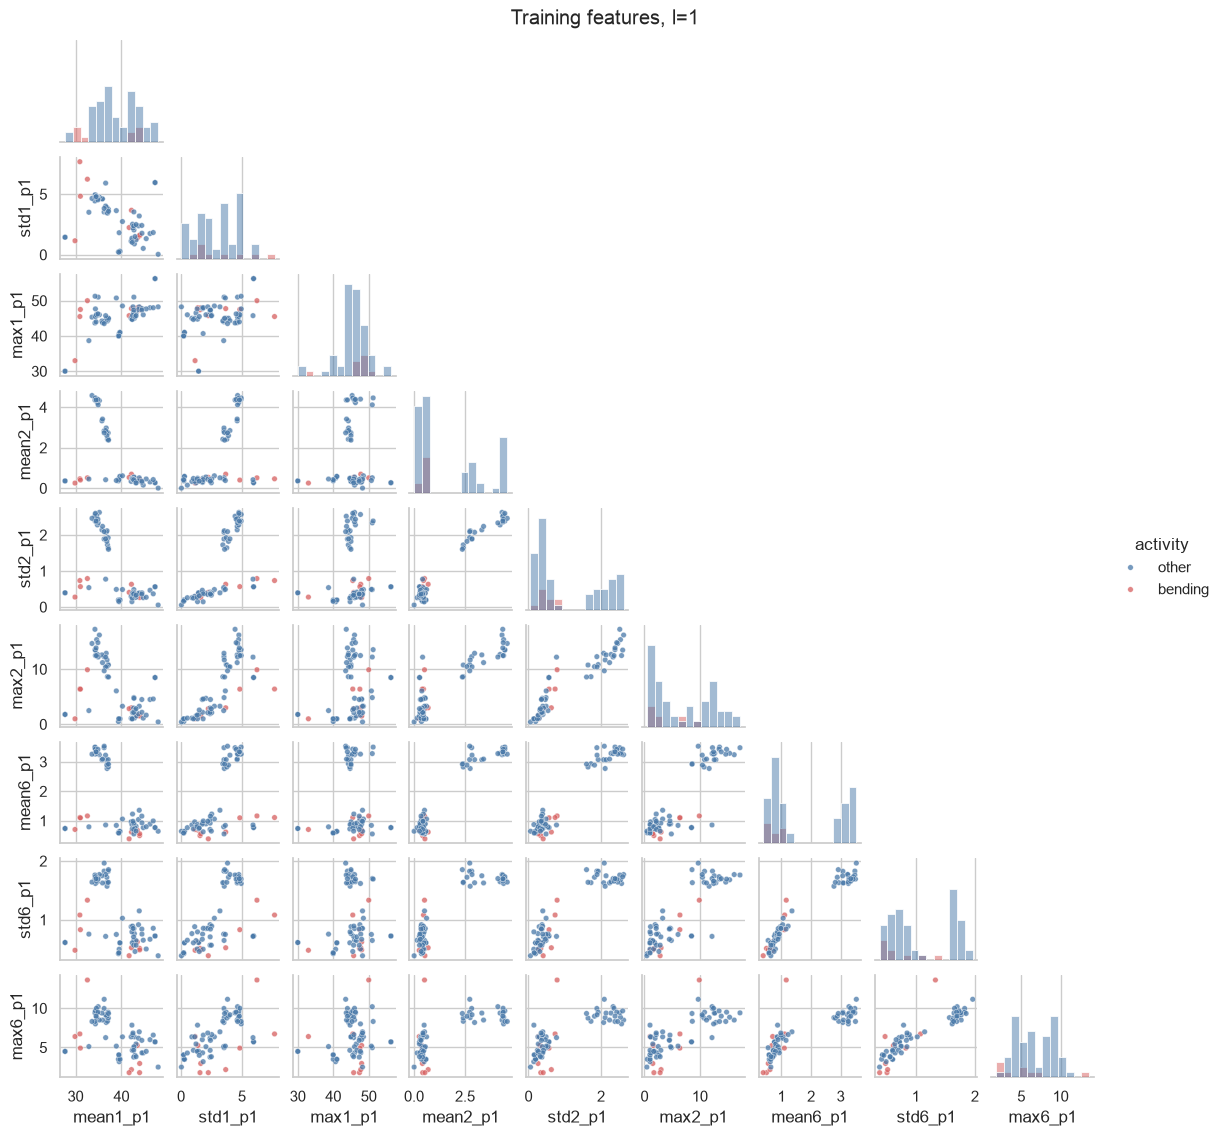

In [4]:
def feature_scatter(l):
    cols = [f'{stat}{i}_part{part}'
            for part in range(1, l + 1)
            for i in [1, 2, 6]
            for stat in ['mean', 'std', 'max']]
    plot_data = X_train[l][cols].copy()
    plot_data.columns = [c.replace('_part', '_p') for c in cols]
    plot_data['activity'] = np.where(y_train == 1, 'bending', 'other')
    grid = sns.pairplot(
        plot_data, hue='activity', hue_order=['other', 'bending'],
        corner=True, diag_kind='hist', height=1.25,
        plot_kws={'s': 16, 'alpha': 0.75}, diag_kws={'bins': 12},
        palette={'other': '#4878a8', 'bending': '#d65f5f'}
    )
    grid.fig.suptitle(f'Training features, l={l}', y=1.01)
    grid.savefig(OUTPUT_DIR / f'scatter_l{l}.png', dpi=140, bbox_inches='tight')
    plt.show()


feature_scatter(1)

### (ii) Split each time series into two parts

There are still 69 training samples. Each sample now has 12 signal segments,
giving 84 features when all seven statistics are included. For the plot,
I use the same three statistics from both halves of time series 1, 2, and 6.

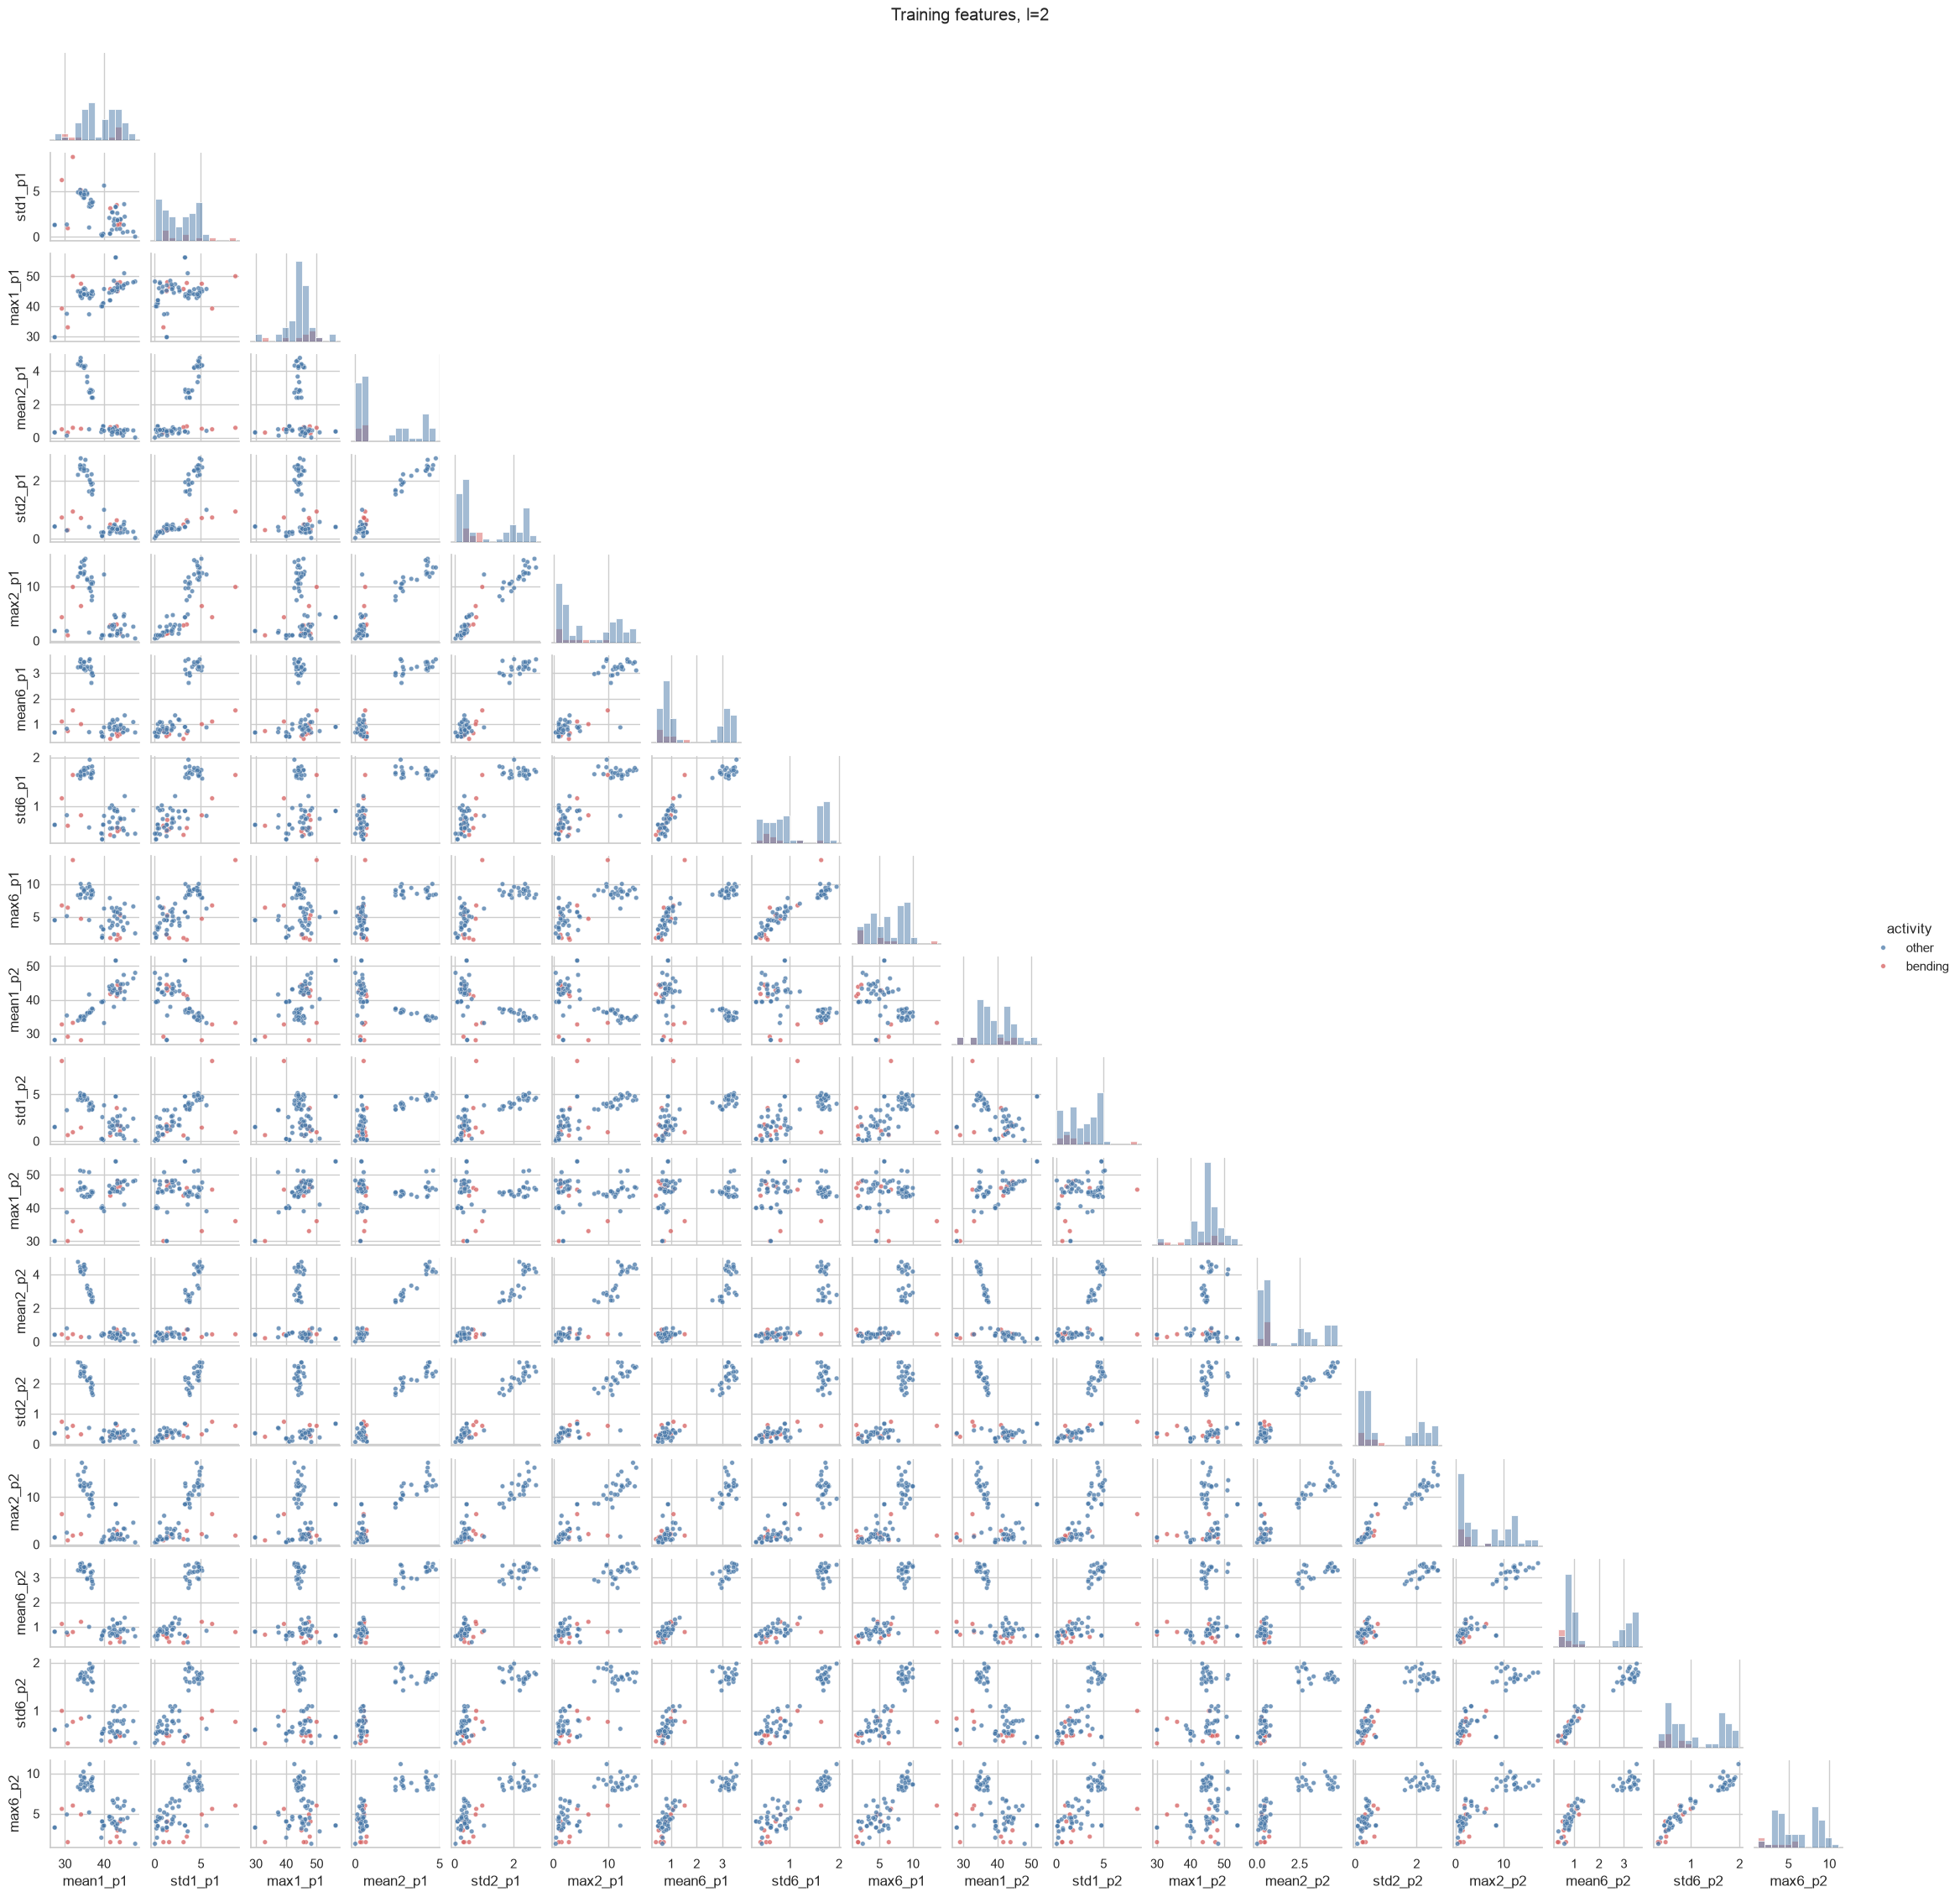

In [5]:
feature_scatter(2)

I do not see a dramatic improvement in separation after splitting into two parts.
The two-part plot retains substantial overlap, especially for the variability
features. Splitting can reveal a change within a recording that its overall
mean or maximum would hide, but it also adds correlated features. The plots
alone do not establish that two segments improve prediction; I compare the
segment counts by cross-validation below.

### (iii) Choose the segment count and number of features

I use 5-fold stratified cross-validation so that each validation fold contains
bending examples. For each fold, I fit the scaler and RFE on the fold's
training samples, then evaluate on its validation samples. Fitting feature
selection or scaling on all 69 samples before cross-validation would leak
information from the validation folds. The 19 test samples are held aside.

I search all segment counts from 1 to 20. The candidate feature counts are
1, 2, 3, 5, 10, 15, 20, 30, 42, and all available features. This is a stated
grid search, rather than an exhaustive search over every possible feature count.
RFE removes 20% of the initial features per iteration to keep the search practical.
I use the assignment's permitted RFE alternative to p-value-based pruning.

The base classifier uses C=1,000,000 to approximate an unpenalized logistic
regression, as allowed in the assignment. This weak penalty keeps the numerical
fit finite when the data are separable. It does not fix the inference problems
caused by separation.

In [6]:
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(
    X_train[1], y_train
))


def logistic_model(C=1e6, l1=False, multiclass=False):
    kwargs = dict(C=C, solver='saga' if multiclass else 'liblinear',
                  max_iter=10000 if multiclass else 3000,
                  tol=1e-4, random_state=SEED)
    if l1:
        # sklearn 1.8+ uses l1_ratio; older releases use penalty='l1'.
        version = tuple(int(x) for x in sklearn.__version__.split('.')[:2])
        kwargs.update({'l1_ratio': 1.0} if version >= (1, 8) else {'penalty': 'l1'})
    return LogisticRegression(**kwargs)


def rfe_model(p):
    return make_pipeline(StandardScaler(), RFE(logistic_model(), n_features_to_select=p,
                                              step=0.2))


rfe_rows = []
for l in range(1, 21):
    candidates = sorted(set([1, 2, 3, 5, 10, 15, 20, 30, 42, 42 * l]))
    for p in candidates:
        scores = []
        for fit_idx, val_idx in folds:
            model = rfe_model(p)
            model.fit(X_train[l].iloc[fit_idx], y_train[fit_idx])
            scores.append(model.score(X_train[l].iloc[val_idx], y_train[val_idx]))
        rfe_rows.append({'l': l, 'p': p, 'cv_accuracy': np.mean(scores),
                         'cv_std': np.std(scores, ddof=1)})
    print(f'RFE: finished l={l}', flush=True)

rfe_results = pd.DataFrame(rfe_rows).sort_values(
    ['cv_accuracy', 'p', 'l'], ascending=[False, True, True]
).reset_index(drop=True)
rfe_results.to_csv(OUTPUT_DIR / 'rfe_cv.csv', index=False)
display(rfe_results.head(10))
best_l = int(rfe_results.loc[0, 'l'])
best_p = int(rfe_results.loc[0, 'p'])
binary_model = rfe_model(best_p).fit(X_train[best_l], y_train)
print('Selected (l, p):', (best_l, best_p))

RFE: finished l=1
RFE: finished l=2
RFE: finished l=3
RFE: finished l=4
RFE: finished l=5
RFE: finished l=6
RFE: finished l=7
RFE: finished l=8
RFE: finished l=9
RFE: finished l=10
RFE: finished l=11
RFE: finished l=12
RFE: finished l=13
RFE: finished l=14
RFE: finished l=15
RFE: finished l=16
RFE: finished l=17
RFE: finished l=18
RFE: finished l=19
RFE: finished l=20


,l,p,cv_accuracy,cv_std
0,3,1,0.985714,0.031944
1,3,3,0.971429,0.039123
2,19,10,0.971429,0.039123
3,6,15,0.971429,0.063888
4,19,15,0.971429,0.039123
5,19,30,0.971429,0.039123
6,3,2,0.957143,0.039123
7,4,2,0.957143,0.039123
8,1,3,0.957143,0.039123
9,4,3,0.957143,0.039123


Selected (l, p): (3, 1)


Ties in cross-validation accuracy are resolved by fewer selected features,
then fewer segments. Cross-validation is used for model selection, so the
winning CV score can be optimistic. The held-out test score is reported later.

### (iv) Training confusion matrix, ROC, coefficients, and p-values

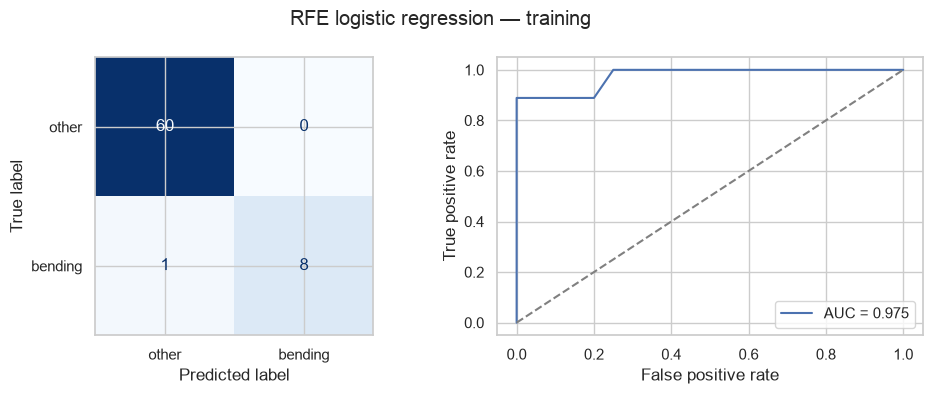

,accuracy,balanced_accuracy,auc
0,0.985507,0.944444,0.975


,feature,beta_standardized,standard_error,wald_p_value
0,intercept,-4.645886,1.372702,0.000713
1,max5_part1,4.586107,1.641117,0.005198


Complete separation: False | complete or quasi separation: False
Information-matrix condition number: 10.3841795610873
These are approximate Wald p-values at the large-C fit, conditional on selection.


In [7]:
def binary_report(model, X, y, title, filename):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay.from_predictions(
        y, pred, labels=[0, 1], display_labels=['other', 'bending'],
        ax=axes[0], colorbar=False, cmap='Blues'
    )
    fpr, tpr, _ = roc_curve(y, prob)
    auc = roc_auc_score(y, prob)
    axes[1].plot(fpr, tpr, label=f'AUC = {auc:.3f}')
    axes[1].plot([0, 1], [0, 1], '--', color='gray')
    axes[1].set(xlabel='False positive rate', ylabel='True positive rate')
    axes[1].legend(loc='lower right')
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches='tight')
    plt.show()
    result = {'accuracy': accuracy_score(y, pred),
              'balanced_accuracy': balanced_accuracy_score(y, pred), 'auc': auc}
    display(pd.DataFrame([result]))
    return result


train_result = binary_report(binary_model, X_train[best_l], y_train,
                             'RFE logistic regression — training', 'binary_train.png')
scaler, selector = binary_model.steps[0][1], binary_model.steps[1][1]
selected_names = X_train[best_l].columns[selector.support_].tolist()
Z = scaler.transform(X_train[best_l])[:, selector.support_]
design = np.column_stack([np.ones(len(Z)), Z])
beta = np.r_[selector.estimator_.intercept_, selector.estimator_.coef_.ravel()]

# Check whether finite, unpenalized maximum-likelihood inference is possible.
signed_design = (2 * y_train - 1)[:, None] * design
complete = linprog(np.zeros(design.shape[1]), A_ub=-signed_design,
                   b_ub=-np.ones(len(Z)), bounds=[(None, None)] * design.shape[1],
                   method='highs').success
quasi = linprog(np.zeros(design.shape[1]),
                A_ub=np.vstack([-signed_design, -signed_design.sum(axis=0)]),
                b_ub=np.r_[np.zeros(len(Z)), -1.0],
                bounds=[(None, None)] * design.shape[1], method='highs').success
prob = expit(design @ beta)
information = design.T @ ((prob * (1 - prob))[:, None] * design)
condition = np.linalg.cond(information)
valid_wald = not quasi and condition < 1e12 and np.linalg.matrix_rank(design) == design.shape[1]
p_values = np.full(len(beta), np.nan)
standard_errors = np.full(len(beta), np.nan)
if valid_wald:
    standard_errors = np.sqrt(np.diag(np.linalg.inv(information)))
    p_values = 2 * norm.sf(np.abs(beta / standard_errors))

coefficients = pd.DataFrame({'feature': ['intercept'] + selected_names,
                             'beta_standardized': beta,
                             'standard_error': standard_errors,
                             'wald_p_value': p_values})
display(coefficients)
coefficients.to_csv(OUTPUT_DIR / 'binary_coefficients.csv', index=False)
print('Complete separation:', complete, '| complete or quasi separation:', quasi)
print('Information-matrix condition number:', condition)
if not valid_wald:
    print('Wald p-values are undefined/unreliable for this fit and are reported as NaN.')
else:
    print('These are approximate Wald p-values at the large-C fit, conditional on selection.')

The coefficients above refer to standardized predictors; the intercept is
for predictors at their training means. With complete or quasi separation,
the ordinary unpenalized logistic MLE does not have finite coefficients,
so ordinary Wald p-values are not valid. In that case I report missing
p-values instead of treating the finite large-C estimates as an ordinary MLE.
Even without separation, these p-values do not account for feature selection.

### (v) Held-out test results

I apply the training segment count, fitted scaler, and selected feature mask
unchanged to the test recordings.

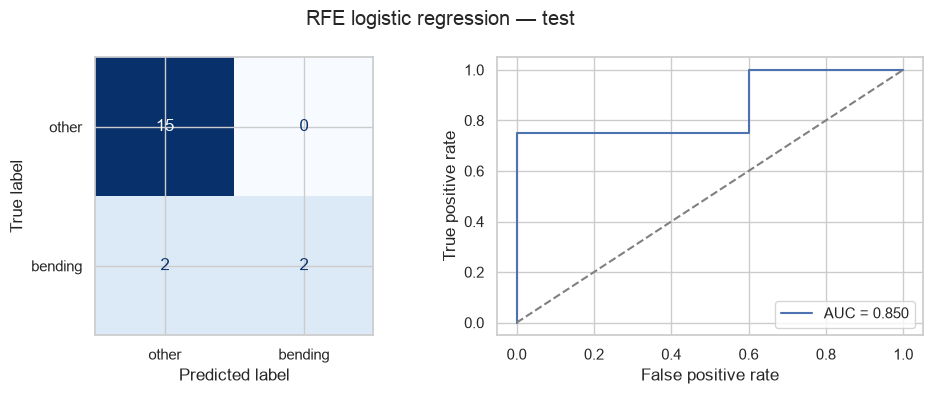

,accuracy,balanced_accuracy,auc
0,0.894737,0.75,0.85


,evaluation,accuracy
0,5-fold CV (selected setting),0.985714
1,training,0.985507
2,test,0.894737


In [8]:
test_result = binary_report(binary_model, X_test[best_l], y_test,
                            'RFE logistic regression — test', 'binary_test.png')
display(pd.DataFrame([
    {'evaluation': '5-fold CV (selected setting)', 'accuracy': rfe_results.loc[0, 'cv_accuracy']},
    {'evaluation': 'training', 'accuracy': train_result['accuracy']},
    {'evaluation': 'test', 'accuracy': test_result['accuracy']}
]))

The test accuracy is 89.47%, below the selected CV accuracy of 98.57%. The model misses two of the four bending test recordings. This suggests that the high CV score overstates performance on this small held-out set.

### (vi) Separation

In [9]:
if complete:
    display(Markdown('The selected training features completely separate the two classes. '
                     'The unpenalized coefficients can grow without bound; a high training '
                     'accuracy does not imply stable coefficients or valid Wald tests.'))
elif quasi:
    display(Markdown('The selected training features show quasi separation. '
                     'Some coefficients can diverge, making ordinary Wald inference unreliable.'))
else:
    display(Markdown('The linear-programming check does not find complete or quasi '
                     'separation in the selected training features. Correlation and the small '
                     'sample size can still make coefficient estimates unstable.'))

The linear-programming check does not find complete or quasi separation in the selected training features. Correlation and the small sample size can still make coefficient estimates unstable.

### (vii) Class imbalance and case-control sampling

There are 9 bending and 60 other training samples. Always predicting other
would already give 60/69 = 86.96% training accuracy, so I also report balanced
accuracy and the confusion matrix.

I sample the minority class with replacement to get 60 observations in each
class. This is case-control sampling: inclusion depends on the class. I keep
the previously chosen l and p, and refit the classifier on the selected,
standardized predictors. For the original population prior, I adjust the
intercept by logit(9/69) - logit(1/2). Duplicating recordings does not create
new independent information.

Intercept adjustment: -1.8971199848858813


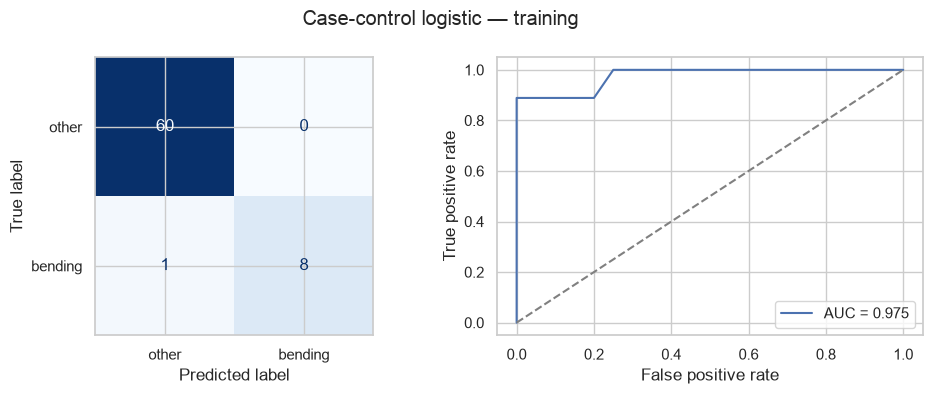

,accuracy,balanced_accuracy,auc
0,0.985507,0.944444,0.975


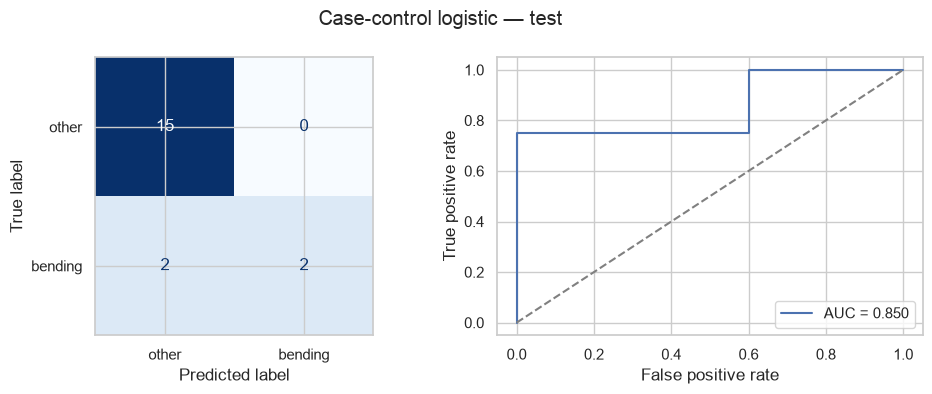

,accuracy,balanced_accuracy,auc
0,0.894737,0.75,0.85


In [10]:
rng = np.random.default_rng(SEED)
other_idx = np.flatnonzero(y_train == 0)
bending_idx = np.flatnonzero(y_train == 1)
sample_idx = np.r_[other_idx, rng.choice(bending_idx, size=len(other_idx), replace=True)]
case_model = logistic_model().fit(Z[sample_idx], y_train[sample_idx])
prior_adjustment = logit(y_train.mean()) - logit(y_train[sample_idx].mean())
case_model.intercept_ += prior_adjustment
print('Intercept adjustment:', prior_adjustment)

# Use the original training scaler and selected feature columns.
Z_test = scaler.transform(X_test[best_l])[:, selector.support_]
case_train_result = binary_report(case_model, Z, y_train,
                                  'Case-control logistic — training', 'case_control_train.png')
case_test_result = binary_report(case_model, Z_test, y_test,
                                 'Case-control logistic — test', 'case_control_test.png')

The intercept correction changes the probability threshold in the original
population. It cannot change the ROC or AUC of a fixed fitted score because
it preserves the ordering of predictions. Resampling and refitting can still
change that ordering. The correction assumes class sampling does not depend
on predictors within each class; the small, nearly separable dataset limits
how accurately the fitted probabilities can be calibrated.

For this run, the corrected case-control model has the same training and test confusion matrices as the original model. It does not improve held-out performance.

## Question 2(b) — L1-penalized binary logistic regression
### (i) Select l and C

I use the same folds and standardize within each training fold. Smaller C
means stronger regularization. I search C in {0.01, 0.1, 1, 10, 100}; zeros in
the fitted coefficients perform feature selection.

Binary L1: finished l=1
Binary L1: finished l=2
Binary L1: finished l=3
Binary L1: finished l=4
Binary L1: finished l=5
Binary L1: finished l=6
Binary L1: finished l=7
Binary L1: finished l=8
Binary L1: finished l=9
Binary L1: finished l=10
Binary L1: finished l=11
Binary L1: finished l=12
Binary L1: finished l=13
Binary L1: finished l=14
Binary L1: finished l=15
Binary L1: finished l=16
Binary L1: finished l=17
Binary L1: finished l=18
Binary L1: finished l=19
Binary L1: finished l=20


,l,C,cv_accuracy,cv_std
0,11,1.0,0.985714,0.031944
1,11,10.0,0.985714,0.031944
2,12,1.0,0.985714,0.031944
3,12,10.0,0.985714,0.031944
4,18,10.0,0.985714,0.031944
5,1,1.0,0.971429,0.039123
6,13,1.0,0.971429,0.039123
7,18,1.0,0.971429,0.039123
8,19,1.0,0.971429,0.039123
9,19,10.0,0.971429,0.039123


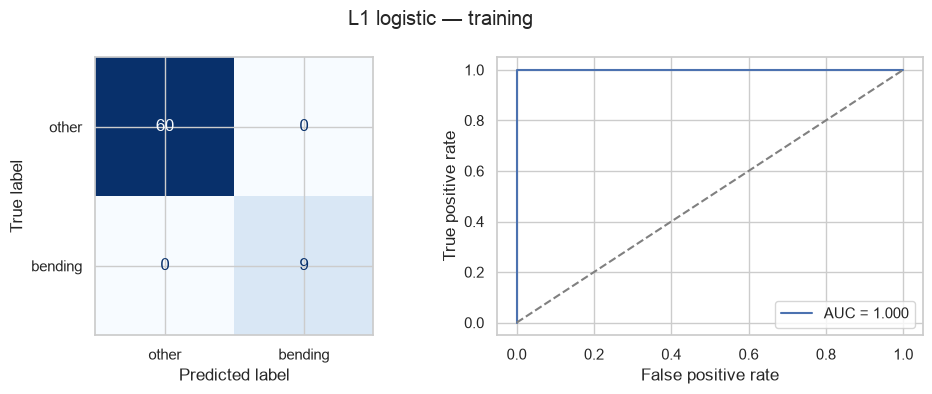

,accuracy,balanced_accuracy,auc
0,1.0,1.0,1.0


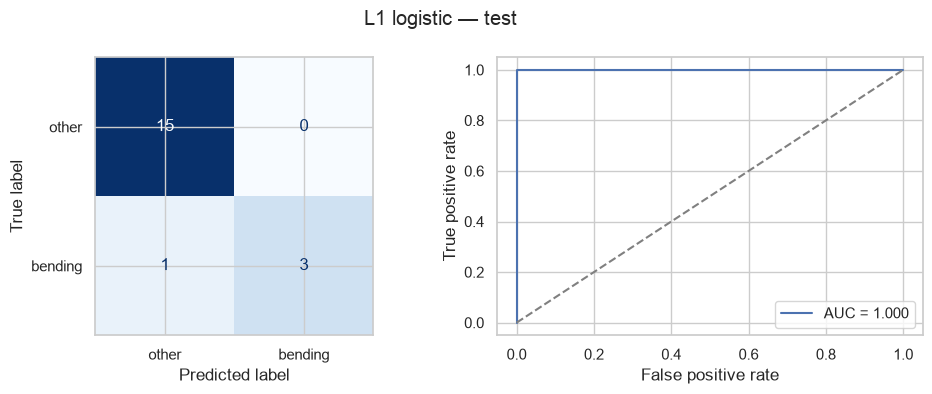

,accuracy,balanced_accuracy,auc
0,0.947368,0.875,1.0


Selected l, C: 11 1.0 | nonzero coefficients: 8


In [11]:
C_VALUES = [0.01, 0.1, 1, 10, 100]
l1_rows = []
for l in range(1, 21):
    for C in C_VALUES:
        scores = []
        for fit_idx, val_idx in folds:
            model = make_pipeline(StandardScaler(), logistic_model(C=C, l1=True))
            model.fit(X_train[l].iloc[fit_idx], y_train[fit_idx])
            scores.append(model.score(X_train[l].iloc[val_idx], y_train[val_idx]))
        l1_rows.append({'l': l, 'C': C, 'cv_accuracy': np.mean(scores),
                        'cv_std': np.std(scores, ddof=1)})
    print(f'Binary L1: finished l={l}', flush=True)

l1_results = pd.DataFrame(l1_rows).sort_values(
    ['cv_accuracy', 'l', 'C'], ascending=[False, True, True]
).reset_index(drop=True)
l1_results.to_csv(OUTPUT_DIR / 'binary_l1_cv.csv', index=False)
display(l1_results.head(10))
l1_l, l1_C = int(l1_results.loc[0, 'l']), float(l1_results.loc[0, 'C'])
l1_model = make_pipeline(StandardScaler(), logistic_model(C=l1_C, l1=True))
l1_model.fit(X_train[l1_l], y_train)
l1_train_result = binary_report(l1_model, X_train[l1_l], y_train,
                                'L1 logistic — training', 'binary_l1_train.png')
l1_test_result = binary_report(l1_model, X_test[l1_l], y_test,
                               'L1 logistic — test', 'binary_l1_test.png')
nonzero = np.count_nonzero(np.abs(l1_model[-1].coef_) > 1e-8)
print('Selected l, C:', l1_l, l1_C, '| nonzero coefficients:', nonzero)

### (ii) Compare the methods

In [12]:
binary_comparison = pd.DataFrame([
    {'method': 'Logistic + RFE', 'l': best_l, 'features': best_p,
     'cv_accuracy': rfe_results.loc[0, 'cv_accuracy'], **{f'test_{k}': v for k, v in test_result.items()}},
    {'method': 'L1 logistic', 'l': l1_l, 'features': nonzero,
     'cv_accuracy': l1_results.loc[0, 'cv_accuracy'], **{f'test_{k}': v for k, v in l1_test_result.items()}}
])
display(binary_comparison)
binary_comparison.to_csv(OUTPUT_DIR / 'binary_comparison.csv', index=False)
if np.isclose(test_result['accuracy'], l1_test_result['accuracy']):
    display(Markdown('The two methods tie on held-out accuracy. Their CV scores, '
                     'AUCs, and feature counts provide additional context.'))
else:
    better = 'L1 logistic regression' if l1_test_result['accuracy'] > test_result['accuracy'] else 'RFE logistic regression'
    display(Markdown(f'{better} has the higher held-out accuracy in this run. '
                     'Only 19 test recordings are available, so this difference is uncertain.'))

,method,l,features,cv_accuracy,test_accuracy,test_balanced_accuracy,test_auc
0,Logistic + RFE,3,1,0.985714,0.894737,0.750,0.85
1,L1 logistic,11,8,0.985714,0.947368,0.875,1.00


L1 logistic regression has the higher held-out accuracy in this run. Only 19 test recordings are available, so this difference is uncertain.

L1 is easier to implement because it combines coefficient fitting and feature
selection in one model. RFE repeatedly fits models, while p-value selection
also requires a valid inferential fit. Separation and strongly correlated
statistics make p-value-based selection particularly awkward here.

## Question 2(c) — Multiclass classification
### (i) L1-penalized multinomial logistic regression

Here bending1 and bending2 are separate classes. I use a joint multinomial
logistic model with the SAGA solver, rather than seven independent binary
models. I tune l and C by stratified 5-fold CV. There are only four bending2
training recordings, so at least one validation fold cannot contain that
class. This is unavoidable with five folds; each training fold still has
all seven classes. For this search I use C in {0.1, 1, 10}.

In [13]:
multi_folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(
    X_train[1], y_train_multi
))
multi_rows = []
convergence_retries = 0
for l in range(1, 21):
    for C in [0.1, 1, 10]:
        scores = []
        for fit_idx, val_idx in multi_folds:
            model = make_pipeline(StandardScaler(), logistic_model(C=C, l1=True, multiclass=True))
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always', ConvergenceWarning)
                model.fit(X_train[l].iloc[fit_idx], y_train_multi[fit_idx])
            if any(issubclass(w.category, ConvergenceWarning) for w in caught):
                convergence_retries += 1
                model[-1].set_params(max_iter=40000, tol=1e-4)
                model.fit(X_train[l].iloc[fit_idx], y_train_multi[fit_idx])
            scores.append(model.score(X_train[l].iloc[val_idx], y_train_multi[val_idx]))
        multi_rows.append({'l': l, 'C': C, 'cv_accuracy': np.mean(scores),
                           'cv_std': np.std(scores, ddof=1)})
    print(f'Multinomial L1: finished l={l}', flush=True)

multi_results = pd.DataFrame(multi_rows).sort_values(
    ['cv_accuracy', 'l', 'C'], ascending=[False, True, True]
).reset_index(drop=True)
multi_results.to_csv(OUTPUT_DIR / 'multinomial_cv.csv', index=False)
display(multi_results.head(10))
multi_l, multi_C = int(multi_results.loc[0, 'l']), float(multi_results.loc[0, 'C'])
multi_model = make_pipeline(StandardScaler(), logistic_model(C=multi_C, l1=True, multiclass=True))
multi_model[-1].set_params(max_iter=40000)
multi_model.fit(X_train[multi_l], y_train_multi)
print('Selected l, C:', multi_l, multi_C)
print('CV fits retried for convergence:', convergence_retries)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(


Multinomial L1: finished l=1
Multinomial L1: finished l=2
Multinomial L1: finished l=3
Multinomial L1: finished l=4
Multinomial L1: finished l=5
Multinomial L1: finished l=6
Multinomial L1: finished l=7
Multinomial L1: finished l=8
Multinomial L1: finished l=9
Multinomial L1: finished l=10
Multinomial L1: finished l=11
Multinomial L1: finished l=12
Multinomial L1: finished l=13
Multinomial L1: finished l=14
Multinomial L1: finished l=15
Multinomial L1: finished l=16
Multinomial L1: finished l=17
Multinomial L1: finished l=18
Multinomial L1: finished l=19
Multinomial L1: finished l=20


,l,C,cv_accuracy,cv_std
0,2,10.0,0.900000,0.063888
1,1,10.0,0.898901,0.038186
2,1,1.0,0.884615,0.095247
3,4,1.0,0.871429,0.078246
4,4,10.0,0.871429,0.078246
5,5,10.0,0.869231,0.033512
6,2,1.0,0.857143,0.112938
7,3,10.0,0.856044,0.086388
8,5,1.0,0.840659,0.031082
9,18,10.0,0.827473,0.079774


Selected l, C: 2 10.0
CV fits retried for convergence: 0


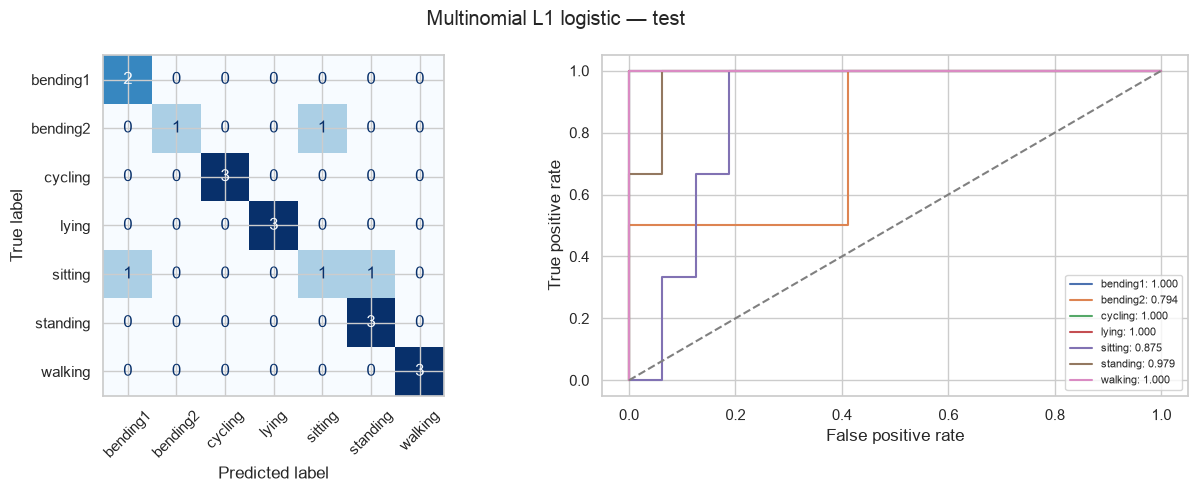

,test_accuracy,test_error,macro_ovr_auc
0,0.842105,0.157895,0.949755


In [14]:
def multiclass_report(model, X, y, title, filename):
    pred = model.predict(X)
    prob = model.predict_proba(X)
    classes = model.classes_
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay.from_predictions(y, pred, labels=classes, ax=axes[0],
                                            xticks_rotation=45, colorbar=False, cmap='Blues')
    indicators = label_binarize(y, classes=classes)
    aucs = []
    for i, label in enumerate(classes):
        fpr, tpr, _ = roc_curve(indicators[:, i], prob[:, i])
        auc = roc_auc_score(indicators[:, i], prob[:, i])
        aucs.append(auc)
        axes[1].plot(fpr, tpr, label=f'{label}: {auc:.3f}')
    axes[1].plot([0, 1], [0, 1], '--', color='gray')
    axes[1].set(xlabel='False positive rate', ylabel='True positive rate')
    axes[1].legend(fontsize=8, loc='lower right')
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / filename, dpi=150, bbox_inches='tight')
    plt.show()
    result = {'test_accuracy': accuracy_score(y, pred),
              'test_error': 1 - accuracy_score(y, pred), 'macro_ovr_auc': np.mean(aucs)}
    display(pd.DataFrame([result]))
    return result


multi_test_result = multiclass_report(multi_model, X_test[multi_l], y_test_multi,
                                      'Multinomial L1 logistic — test', 'multinomial_test.png')

The multiclass confusion matrix has actual classes in rows and predicted
classes in columns. A diagonal entry is a correct prediction. For ROC, I
treat each class as positive and all other classes as negative (one versus
rest), using that class's predicted probability. Macro AUC is the unweighted
mean of the seven class AUCs. These plots describe held-out predictions;
they are not used to retune the models.

### (ii) Gaussian and multinomial Naive Bayes

I choose l by the same stratified CV. GaussianNB models each feature with a
class-conditional Gaussian distribution. MultinomialNB uses multinomial
feature likelihoods. These are likelihood assumptions, rather than choices
of Gaussian versus multinomial class priors.

The extracted statistics are nonnegative. I use raw features for GaussianNB
and a training-fold MinMaxScaler for MultinomialNB so larger-scale RSS
features do not automatically dominate. `clip=True` keeps validation and
test values nonnegative when they fall outside the training range. The
statistics are continuous, not counts, so the multinomial assumption is
only an approximation. I keep the other NB parameters at their defaults
and select l for each method.

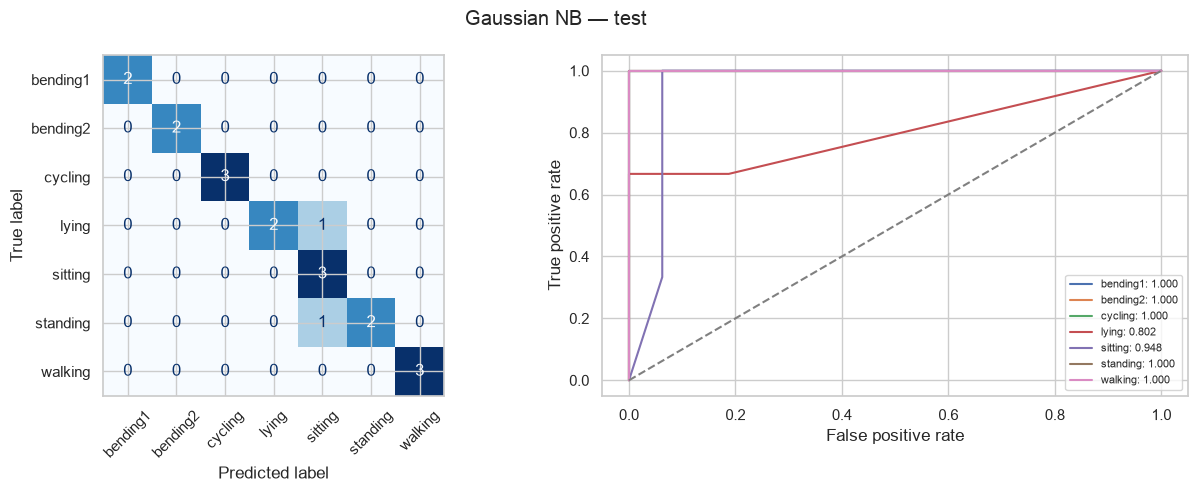

,test_accuracy,test_error,macro_ovr_auc
0,0.894737,0.105263,0.964286


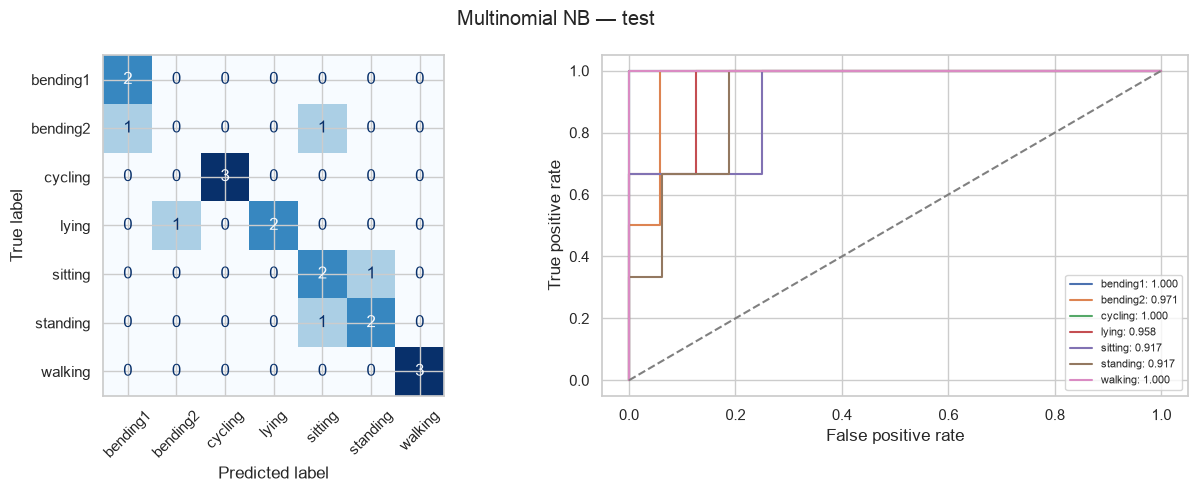

,test_accuracy,test_error,macro_ovr_auc
0,0.736842,0.263158,0.966036


,method,l,cv_accuracy,test_accuracy,test_error,macro_ovr_auc
0,Multinomial L1 logistic,2,0.900000,0.842105,0.157895,0.949755
1,Gaussian NB,1,0.869231,0.894737,0.105263,0.964286
2,Multinomial NB,5,0.752747,0.736842,0.263158,0.966036


In [15]:
def nb_model(kind):
    if kind == 'Gaussian NB':
        return GaussianNB()
    return make_pipeline(MinMaxScaler(clip=True), MultinomialNB(alpha=1.0))


nb_rows = []
for kind in ['Gaussian NB', 'Multinomial NB']:
    for l in range(1, 21):
        scores = []
        for fit_idx, val_idx in multi_folds:
            model = nb_model(kind)
            model.fit(X_train[l].iloc[fit_idx], y_train_multi[fit_idx])
            scores.append(model.score(X_train[l].iloc[val_idx], y_train_multi[val_idx]))
        nb_rows.append({'method': kind, 'l': l, 'cv_accuracy': np.mean(scores),
                        'cv_std': np.std(scores, ddof=1)})

nb_results = pd.DataFrame(nb_rows)
nb_results.to_csv(OUTPUT_DIR / 'naive_bayes_cv.csv', index=False)
multi_comparison = [{'method': 'Multinomial L1 logistic', 'l': multi_l,
                      'cv_accuracy': multi_results.loc[0, 'cv_accuracy'], **multi_test_result}]
for kind in ['Gaussian NB', 'Multinomial NB']:
    best = nb_results[nb_results['method'] == kind].sort_values(
        ['cv_accuracy', 'l'], ascending=[False, True]).iloc[0]
    l = int(best['l'])
    model = nb_model(kind).fit(X_train[l], y_train_multi)
    result = multiclass_report(model, X_test[l], y_test_multi,
                               kind + ' — test', kind.lower().replace(' ', '_') + '_test.png')
    multi_comparison.append({'method': kind, 'l': l,
                             'cv_accuracy': best['cv_accuracy'], **result})

multi_comparison = pd.DataFrame(multi_comparison)
display(multi_comparison)
multi_comparison.to_csv(OUTPUT_DIR / 'multiclass_comparison.csv', index=False)

### (iii) Which method performs better?

In [16]:
best_cv = multi_comparison.loc[multi_comparison['cv_accuracy'].idxmax()]
best_test = multi_comparison.loc[multi_comparison['test_accuracy'].idxmax()]
display(Markdown(
    f"The highest CV accuracy is **{best_cv['cv_accuracy']:.3f}**, from "
    f"**{best_cv['method']}**. The highest observed test accuracy is "
    f"**{best_test['test_accuracy']:.3f}**, from **{best_test['method']}**. "
    "The table shows any ties. I use CV to select settings and report all three "
    "test results for comparison; I do not tune settings to the test set. "
    "With only 19 test recordings, one mistake changes accuracy by about 5.3 percentage points."
))

The highest CV accuracy is **0.900**, from **Multinomial L1 logistic**. The highest observed test accuracy is **0.895**, from **Gaussian NB**. The table shows any ties. I use CV to select settings and report all three test results for comparison; I do not tune settings to the test set. With only 19 test recordings, one mistake changes accuracy by about 5.3 percentage points.

## Question 3 — ISLR 4.8.3

For class $k$, let $\pi_k=P(Y=k)$ and
$X\mid Y=k\sim N(\mu_k,\sigma_k^2)$. By Bayes' theorem,

$$P(Y=k\mid X=x)=\frac{\pi_k f_k(x)}{\sum_{j=1}^K\pi_j f_j(x)}.$$

The denominator is the same for every class. Therefore, the Bayes classifier
chooses the class with the largest log numerator:

$$\log\pi_k-\frac12\log(2\pi\sigma_k^2)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Dropping the common term $-\tfrac12\log(2\pi)$ and expanding the square gives

$$\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\frac12\log\sigma_k^2+\log\pi_k.$$

When the class variances differ, the coefficient of $x^2$ depends on the
class and cannot generally be removed from the comparison. In particular,
the boundary between classes $k$ and $j$ satisfies

$$\left(\frac{1}{2\sigma_j^2}-\frac{1}{2\sigma_k^2}\right)x^2
+\left(\frac{\mu_k}{\sigma_k^2}-\frac{\mu_j}{\sigma_j^2}\right)x
+\log\frac{\pi_k}{\pi_j}
-\frac12\log\frac{\sigma_k^2}{\sigma_j^2}
-\frac{\mu_k^2}{2\sigma_k^2}
+\frac{\mu_j^2}{2\sigma_j^2}=0.$$

This is generally a quadratic equation, so the discriminant is quadratic,
not linear. Equal variances are a special case: the quadratic terms cancel
and the comparison reduces to a linear discriminant.

## Question 4 — ISLR 4.8.7

Let $D$ mean that the company issues a dividend. The given quantities are

$$\pi_D=0.8,\qquad \pi_N=0.2,\qquad
\mu_D=10,\qquad\mu_N=0,\qquad\sigma^2=36.$$

At $X=4$, Bayes' theorem gives

$$P(D\mid X=4)=\frac{0.8f_D(4)}{0.8f_D(4)+0.2f_N(4)}.$$

The common normal-density constant cancels, so

$$P(D\mid X=4)=
\frac{0.8e^{-(4-10)^2/72}}
{0.8e^{-(4-10)^2/72}+0.2e^{-4^2/72}}
=\frac{1}{1+0.25e^{5/18}}
\approx 0.75185.$$

Thus the estimated probability of issuing a dividend is about **75.2%**.

In [17]:
p_dividend = 1 / (1 + 0.25 * np.exp(5 / 18))
print(f'P(dividend | X=4) = {p_dividend:.6f}')

P(dividend | X=4) = 0.751852
